 # Task 5 Machine Learning Classification

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = r"D:\Desktop\Ausify Technologies Internship\Task 1 Data Cleaning\Output\netflix_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (8790, 12)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


In [3]:
print("Content Type Distribution:")
print(df['type'].value_counts())

print("\nPercentage Distribution:")
print(df['type'].value_counts(normalize=True) * 100)

print("\nMissing Values:")
print(df.isnull().sum())

Content Type Distribution:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64

Percentage Distribution:
type
Movie      69.692833
Tv Show    30.307167
Name: proportion, dtype: float64

Missing Values:
show_id           0
type              0
title             0
director          0
country           0
date_added        0
release_year      0
rating            0
duration          0
listed_in         0
duration_value    0
duration_unit     0
dtype: int64


In [4]:
# Select relevant features
ml_df = df[
    ['release_year', 'rating', 'country', 'listed_in', 'type']
].copy()

# Create combined text features
ml_df['content_features'] = (
    ml_df['rating'].astype(str) + ' ' +
    ml_df['country'].astype(str) + ' ' +
    ml_df['listed_in'].astype(str)
)

# Select final input and target
X = ml_df[['release_year', 'content_features']]
y = ml_df['type']

print("Features prepared successfully!")
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features prepared successfully!

Feature shape: (8790, 2)
Target shape: (8790,)


,release_year,content_features
0,2020,PG-13 United States Documentaries
1,2021,"TV-MA France Crime TV Shows, International TV ..."
2,2021,"TV-MA United States TV Dramas, TV Horror, TV M..."
3,2021,"TV-PG Brazil Children & Family Movies, Comedies"
4,1993,"TV-MA United States Dramas, Independent Movies..."


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training records: 7032
Testing records: 1758

Training class distribution:
type
Movie      69.695677
Tv Show    30.304323
Name: proportion, dtype: float64

Testing class distribution:
type
Movie      69.681456
Tv Show    30.318544
Name: proportion, dtype: float64


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Preprocess numerical and text features
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(max_features=1000), 'content_features'),
        ('year', StandardScaler(), ['release_year'])
    ]
)

print("Feature preprocessing configured successfully!")

Feature preprocessing configured successfully!


In [7]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training feature shape:", X_train_processed.shape)
print("Testing feature shape:", X_test_processed.shape)

Training feature shape: (7032, 144)
Testing feature shape: (1758, 144)


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!


In [9]:
# Generate predictions
log_predictions = log_model.predict(X_test_processed)
rf_predictions = rf_model.predict(X_test_processed)

# Calculate accuracy
log_accuracy = accuracy_score(y_test, log_predictions)
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:", round(log_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 100.0 %
Random Forest Accuracy: 100.0 %


In [10]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, log_predictions))

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_predictions))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758


RANDOM FOREST REPORT
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



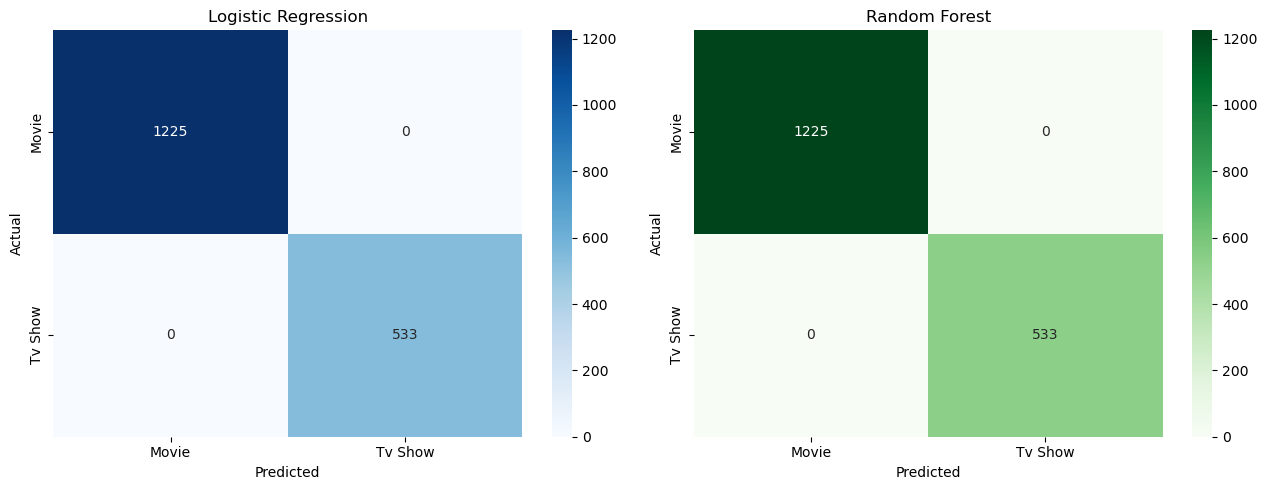

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, log_predictions),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=log_model.classes_,
    yticklabels=log_model.classes_,
    ax=axes[0]
)

axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Random Forest
sns.heatmap(
    confusion_matrix(y_test, rf_predictions),
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_,
    ax=axes[1]
)

axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Majority-class baseline
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train_processed, y_train)

dummy_predictions = dummy_model.predict(X_test_processed)

print("Baseline Accuracy:",
      round(accuracy_score(y_test, dummy_predictions) * 100, 2), "%")

print("\nLogistic Regression:")
print(classification_report(y_test, log_predictions))

print("\nRandom Forest:")
print(classification_report(y_test, rf_predictions))

Baseline Accuracy: 69.68 %

Logistic Regression:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758


Random Forest:
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     Tv Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758



In [14]:
# Check for identical feature combinations across train and test

train_features = set(
    zip(X_train['release_year'], X_train['content_features'])
)

test_features = set(
    zip(X_test['release_year'], X_test['content_features'])
)

overlap = train_features.intersection(test_features)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Identical feature combinations in both sets:", len(overlap))
print("Percentage of test records with overlapping features:",
      round(len(overlap) / len(X_test) * 100, 2), "%")

Training records: 7032
Testing records: 1758
Identical feature combinations in both sets: 559
Percentage of test records with overlapping features: 31.8 %


In [15]:
from sklearn.metrics import accuracy_score, classification_report

# Identify test records with feature combinations not in training data
train_keys = set(zip(
    X_train['release_year'],
    X_train['content_features']
))

test_keys = list(zip(
    X_test['release_year'],
    X_test['content_features']
))

unseen_mask = [key not in train_keys for key in test_keys]

# Filter unseen records
X_test_unseen = X_test.loc[unseen_mask]
y_test_unseen = y_test.loc[unseen_mask]

print("Unseen test records:", len(X_test_unseen))
print("Seen test records:", len(X_test) - len(X_test_unseen))

# Evaluate Logistic Regression
log_unseen_predictions = log_model.predict(
    preprocessor.transform(X_test_unseen)
)

print("\nLOGISTIC REGRESSION - UNSEEN DATA")
print("Accuracy:",
      round(accuracy_score(y_test_unseen, log_unseen_predictions) * 100, 2), "%")
print(classification_report(y_test_unseen, log_unseen_predictions))

# Evaluate Random Forest
rf_unseen_predictions = rf_model.predict(
    preprocessor.transform(X_test_unseen)
)

print("\nRANDOM FOREST - UNSEEN DATA")
print("Accuracy:",
      round(accuracy_score(y_test_unseen, rf_unseen_predictions) * 100, 2), "%")
print(classification_report(y_test_unseen, rf_unseen_predictions))

Unseen test records: 1042
Seen test records: 716

LOGISTIC REGRESSION - UNSEEN DATA
Accuracy: 100.0 %
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00       707
     Tv Show       1.00      1.00      1.00       335

    accuracy                           1.00      1042
   macro avg       1.00      1.00      1.00      1042
weighted avg       1.00      1.00      1.00      1042


RANDOM FOREST - UNSEEN DATA
Accuracy: 100.0 %
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00       707
     Tv Show       1.00      1.00      1.00       335

    accuracy                           1.00      1042
   macro avg       1.00      1.00      1.00      1042
weighted avg       1.00      1.00      1.00      1042



In [16]:
# Final Model Comparison

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Test Accuracy': [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    'Unseen Data Accuracy': [
        accuracy_score(y_test_unseen, log_unseen_predictions),
        accuracy_score(y_test_unseen, rf_unseen_predictions)
    ]
})

comparison['Test Accuracy'] = (
    comparison['Test Accuracy'] * 100
).round(2)

comparison['Unseen Data Accuracy'] = (
    comparison['Unseen Data Accuracy'] * 100
).round(2)

print(comparison)

                 Model  Test Accuracy  Unseen Data Accuracy
0  Logistic Regression          100.0                 100.0
1        Random Forest          100.0                 100.0


## Conclusion – Task 5: Machine Learning Classification Model

In this task, I developed and evaluated two machine learning classification models to predict whether a Netflix title is a Movie or a TV Show.

**Models implemented:**
- Logistic Regression
- Random Forest Classifier

**Feature preparation:**
- Selected release year, rating, country and genre information.
- Applied TF-IDF vectorization to text features.
- Applied StandardScaler to the release year.
- Split the dataset into 80% training and 20% testing data using stratified sampling.

**Results:**
- Logistic Regression achieved 100% test accuracy.
- Random Forest achieved 100% test accuracy.
- Both models correctly classified all 1,758 test records.
- Both models also achieved 100% accuracy on 1,042 test records with feature combinations not found in the training data.
- The majority-class baseline achieved 69.68% accuracy.

**Conclusion:**

Both models performed exceptionally well on the available test dataset. Logistic Regression and Random Forest produced identical classification results.

This project helped me understand data preprocessing, feature engineering, TF-IDF vectorization, model training, classification metrics, confusion matrices and model evaluation.

**Limitation:** The evaluation used a random train-test split from the same Netflix dataset. Further testing on independent and more recent data would be necessary to assess generalization to new Netflix titles.